In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from imblearn.over_sampling import SMOTE

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

C:\Users\mi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('/kaggle/input/datasets/fedesoriano/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv')

df.drop('id',axis=1,inplace=True)
df['bmi'].fillna(df['bmi'].median(), inplace=True)

df.info()

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/fedesoriano/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv'

In [ ]:
x = df.drop('stroke',axis=1)
y = df['stroke']

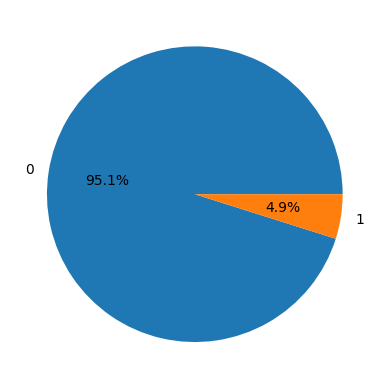

In [ ]:
vc = df['stroke'].value_counts()
plt.pie(vc.values,labels=vc.index,autopct='%1.1f%%')
plt.show()

In [ ]:
cat_features = []
for i in x.columns:
    if x[i].dtype == 'object':
        cat_features.append(i)

x_train,x_test,y_train,y_test = train_test_split(
    x,y,random_state=42,train_size=0.8,stratify=y
)

In [ ]:
cat = CatBoostClassifier(
    cat_features=cat_features,
    class_weights=[1.0, 15.0],        
    iterations=1000,                
    learning_rate=0.03,             
    random_state=42,                
    verbose=100                     
)

cat.fit(x_train,y_train)
cat.score(x_test,y_test)

0:	learn: 0.6776138	total: 61.2ms	remaining: 1m 1s
100:	learn: 0.4323986	total: 503ms	remaining: 4.48s
200:	learn: 0.3897601	total: 955ms	remaining: 3.8s
300:	learn: 0.3440907	total: 1.43s	remaining: 3.32s
400:	learn: 0.2610230	total: 1.99s	remaining: 2.97s
500:	learn: 0.2119244	total: 2.54s	remaining: 2.53s
600:	learn: 0.1734251	total: 3.11s	remaining: 2.06s
700:	learn: 0.1464187	total: 3.68s	remaining: 1.57s
800:	learn: 0.1255298	total: 4.24s	remaining: 1.05s
900:	learn: 0.1096709	total: 4.79s	remaining: 526ms
999:	learn: 0.0953468	total: 5.35s	remaining: 0us


np.float64(0.9227005870841487)

In [ ]:
y_pred = cat.predict(x_test)
y_pred_proba = cat.predict_proba(x_test)[:, 1]

roc_auc_score(y_test, y_pred_proba)

np.float64(0.8211728395061728)

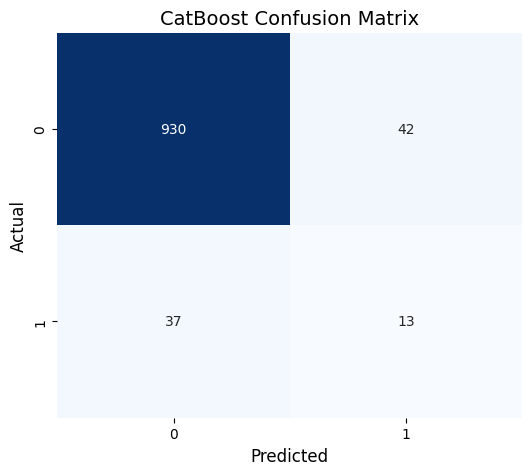

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test, y_pred), 
    annot=True,    
    fmt='d',        
    cmap='Blues',   
    cbar=False
)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.title('CatBoost Confusion Matrix', fontsize=14)
plt.show()

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.96      0.96       972
           1       0.24      0.26      0.25        50

    accuracy                           0.92      1022
   macro avg       0.60      0.61      0.60      1022
weighted avg       0.93      0.92      0.92      1022



In [3]:

import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    precision_recall_curve
)
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

df.drop('id',axis=1,inplace=True)
df['bmi'].fillna(df['bmi'].median(), inplace=True)

x = df.drop('stroke',axis=1)
y = df['stroke']
X = x.drop(columns=["id"], errors="ignore").copy()
y = y.copy()



# Identify categorical columns
cat_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Make categorical values consistent
for col in cat_features:
    X[col] = X[col].fillna("Missing").astype(str)

# Split off the final test set
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.20,
    random_state=42,
    stratify=y_trainval
)

# Train CatBoost
cat = CatBoostClassifier(
    cat_features=cat_features,
    class_weights=[1.0, 15.0],
    iterations=1000,
    learning_rate=0.03,
    depth=6,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

cat.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    verbose=100
)

# Choose a threshold using validation predictions
val_proba = cat.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, val_proba
)

# Select threshold with the best validation F1-score
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Selected validation threshold:", best_threshold)
print("Validation F1-score:", f1_scores[best_idx])

# Evaluate once on the untouched test set
test_proba = cat.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

print("\nTest classification report:")
print(classification_report(
    y_test, test_pred,
    labels=[0, 1],
    target_names=["No Stroke", "Stroke"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred))

print("ROC-AUC:", roc_auc_score(y_test, test_proba))
print("PR-AUC:", average_precision_score(y_test, test_proba))


C:\Users\mi\AppData\Local\Temp\ipykernel_12472\3371184935.py:17: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['bmi'].fillna(df['bmi'].median(), inplace=True)


0:	learn: 0.6790685	test: 0.6795394	best: 0.6795394 (0)	total: 184ms	remaining: 3m 4s
100:	learn: 0.4160956	test: 0.4687350	best: 0.4666210 (94)	total: 3.77s	remaining: 33.5s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4666209576
bestIteration = 94

Shrink model to first 95 iterations.
Selected validation threshold: 0.6560666718523355
Validation F1-score: 0.2782608695647637

Test classification report:
              precision    recall  f1-score   support

   No Stroke       0.97      0.93      0.95       972
      Stroke       0.27      0.52      0.36        50

    accuracy                           0.91      1022
   macro avg       0.62      0.72      0.65      1022
weighted avg       0.94      0.91      0.92      1022

Confusion matrix:
[[902  70]
 [ 24  26]]
ROC-AUC: 0.8440329218106997
PR-AUC: 0.25378156164259
